# Smoothness × recency — five-seed analysis

**Primary:** paired ID-dev Binding difference between `smooth_early` and `step_early`, and between `smooth_late` and `step_late`, at step 9,000. Both smoothness contrasts match exposure counts, the exact mean timing of Binding presentations, and first/last-window task proportions. **Secondary:** effect of earlier versus later Binding exposure, OOD behavior, prior-task retention, and prediction changes.

In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = Path().cwd().parent.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

SEEDS = [42, 43, 44, 45, 46]
DATA_DIR = PROJECT_ROOT / "outputs/medium_world/dataset"
OUT_DIR = PROJECT_ROOT / "outputs/medium_world/experiments/smoothness_recency/five_seeds"
RESULTS_FILE = OUT_DIR / "schedule_comparison.json"

In [2]:
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.medium_visual_world.learning import TASKS
from src.medium_visual_world.generate import read_jsonl
from src.medium_visual_world.smoothness_recency import STRATEGIES, PROFILES, profile_stats
from src.medium_visual_world.prediction_tracking import (
    load_trace, compare_two, compare_three, summarize_changes, scene_context
)

report = json.loads(RESULTS_FILE.read_text(encoding="utf-8"))
assert report["config"]["design"] == "smoothness_recency_v1"
assert report["config"]["strategies"] == list(STRATEGIES)
assert report["config"]["prefix_steps"] == 6300 and report["config"]["total_steps"] == 9000
for name, digest in report["dataset_hashes"].items():
    assert hashlib.sha256((DATA_DIR / name).read_bytes()).hexdigest() == digest
runs = sorted(report["runs"], key=lambda r:(r["seed"],r["schedule"]))
assert len(runs) == 20
assert {(r["seed"],r["schedule"]) for r in runs} == {(s,k) for s in SEEDS for k in STRATEGIES}
traces = {}
for r in runs:
    assert r["status"] == "completed" and r["steps_run"] == 9000
    assert len(r["history"]) == 91 and r["parent_seed"] == r["seed"]
    assert all(r["final"]["cumulative_task_presentations"].get(t,0)==112500 for t in TASKS)
    t = load_trace(OUT_DIR / r["prediction_trace"])
    assert t["metadata"]["parent_sha256"] == r["parent_sha256"]
    for split,n in (("id_dev",1024),("ood_dev",400)):
        b = t["splits"][split]
        assert b["predictions"].shape == (91,n)
        assert np.array_equal(b["steps"],np.arange(0,9001,100))
    traces[(r["seed"],r["schedule"])] = t
for seed in SEEDS:
    related = [r for r in runs if r["seed"]==seed]
    assert len({r["parent_sha256"] for r in related})==1
    ref = traces[(seed,STRATEGIES[0])]
    for strategy in STRATEGIES[1:]:
        other = traces[(seed,strategy)]
        for split in ("id_dev","ood_dev"):
            assert np.array_equal(ref["splits"][split]["predictions"][:64],
                                  other["splits"][split]["predictions"][:64])
            assert np.array_equal(ref["splits"][split]["probabilities"][:64],
                                  other["splits"][split]["probabilities"][:64])
print("PASS: 20 runs, five verified shared parents, 91 checkpoints each")

PASS: 20 runs, five verified shared parents, 91 checkpoints each


## Design checks

Each strategy presents exactly 67,500 Binding and 22,500 examples of each earlier task after branching. For each recency level, the smooth and stepwise conditions have identical Binding exposure centroids and 300-step start/end proportions. The mean Binding exposure step differs by 600 between early and late conditions.

,strategy,pair_percentage_by_window,mean_pair_window,mean_pair_optimizer_step,max_adjacent_percentage_point_jump,squared_jump_score
0,smooth_early,"[80, 70, 65, 60, 50, 45, 35, 25, 20]",4.0,7350.0,10,500
1,step_early,"[80, 74, 74, 46, 46, 46, 32, 32, 20]",4.0,7350.0,28,1160
2,smooth_late,"[20, 25, 35, 45, 50, 60, 65, 70, 80]",6.0,7950.0,10,500
3,step_late,"[20, 32, 32, 46, 46, 46, 74, 74, 80]",6.0,7950.0,28,1160


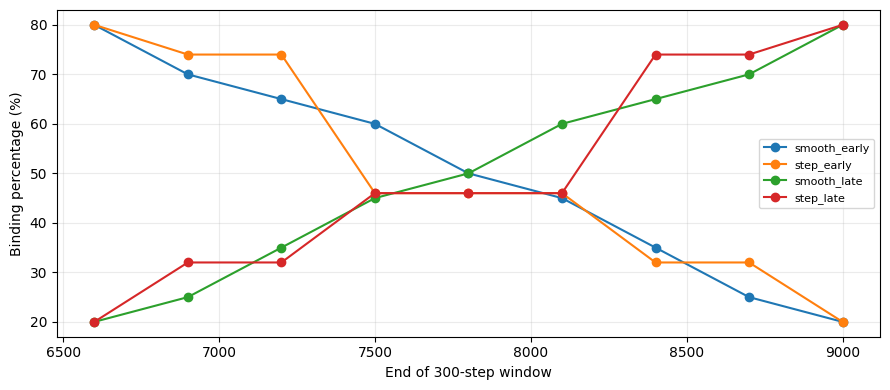

In [3]:
design = pd.DataFrame([{"strategy":s,**profile_stats(PROFILES[s])} for s in STRATEGIES])
display(design)
for recency in ("early","late"):
    a,b = design.set_index("strategy").loc[[f"smooth_{recency}",f"step_{recency}"]].to_dict("records")
    assert a["mean_pair_optimizer_step"] == b["mean_pair_optimizer_step"]
    assert a["pair_percentage_by_window"][0] == b["pair_percentage_by_window"][0]
    assert a["pair_percentage_by_window"][-1] == b["pair_percentage_by_window"][-1]
fig,ax = plt.subplots(figsize=(9,4))
for s in STRATEGIES:
    ax.plot(np.arange(1,10)*300+6300,PROFILES[s],marker="o",label=s)
ax.set(xlabel="End of 300-step window",ylabel="Binding percentage (%)")
ax.grid(alpha=.25);ax.legend(fontsize=8)
fig.tight_layout();fig.savefig(OUT_DIR/"training_allocation_profiles.png",dpi=160);plt.show()

## Final Binding results and paired comparisons

Primary inference uses paired seed differences at the fixed final step. Confidence intervals use Student's *t* with four degrees of freedom; report each seed rather than selecting the best run.

In [4]:
final_rows=[]
for r in runs:
    h = r["history"][-1]
    for split in ("id_dev","ood_dev"):
        for task,accuracy in h[split]["by_template"].items():
            binary=h[split]["binary_by_template"][task]
            final_rows.append({"seed":r["seed"],"strategy":r["schedule"],
                               "split":split,"task":task,"accuracy":accuracy,
                               "cross_entropy":h[split]["loss_by_template"][task],
                               "positive_recall":binary["positive_recall"],
                               "negative_specificity":binary["negative_specificity"],
                               "predicted_positive_rate":binary["predicted_positive_rate"]})
final=pd.DataFrame(final_rows)
final.to_csv(OUT_DIR/"final_by_seed.csv",index=False)
summary=final.groupby(["strategy","split","task"],as_index=False).agg(
    mean_accuracy=("accuracy","mean"),sd_accuracy=("accuracy","std"),
    positive_recall=("positive_recall","mean"),
    negative_specificity=("negative_specificity","mean"))
display(summary[summary.task=="pair"])

comparisons=[("smooth_early","step_early"),("smooth_late","step_late"),
             ("smooth_late","smooth_early"),("step_late","step_early"),
             ("smooth_early","smooth_late"),("step_early","step_late")]
paired=[]
for split in ("id_dev","ood_dev"):
    tab=final[(final.split==split)&(final.task=="pair")].pivot(
        index="seed",columns="strategy",values="accuracy")
    effects=[(a+" - "+b,tab[a]-tab[b]) for a,b in comparisons]
    interaction=(tab["smooth_late"]-tab["step_late"])-(
        tab["smooth_early"]-tab["step_early"])
    effects.append(("smoothness × recency interaction",interaction))
    for label,d in effects:
        d=d.sort_index();n=len(d);mean=float(d.mean())
        se=float(d.std(ddof=1)/np.sqrt(n))
        paired.append({"split":split,"comparison":label,"n_seeds":n,
                       "mean_difference":mean,"ci95_low":mean-2.776445105*se,
                       "ci95_high":mean+2.776445105*se,
                       "wins":int((d>0).sum()),"ties":int((d==0).sum()),
                       **{f"seed_{seed}":float(v) for seed,v in d.items()}})
paired=pd.DataFrame(paired)
paired.to_csv(OUT_DIR/"paired_differences.csv",index=False)
display(paired)

,strategy,split,task,mean_accuracy,sd_accuracy,positive_recall,negative_specificity
2,smooth_early,id_dev,pair,0.654687,0.027148,0.756250,0.553125
4,smooth_early,ood_dev,pair,0.587000,0.027579,0.669000,0.505000
7,smooth_late,id_dev,pair,0.653906,0.025255,0.768750,0.539062
9,smooth_late,ood_dev,pair,0.593500,0.036469,0.715000,0.472000
12,step_early,id_dev,pair,0.650000,0.029826,0.753125,0.546875
14,step_early,ood_dev,pair,0.591000,0.038308,0.656000,0.526000
17,step_late,id_dev,pair,0.652344,0.023600,0.771875,0.532813
19,step_late,ood_dev,pair,0.598000,0.036030,0.715000,0.481000


,split,comparison,n_seeds,mean_difference,ci95_low,ci95_high,wins,ties,seed_42,seed_43,seed_44,seed_45,seed_46
0,id_dev,smooth_early - step_early,5,0.004687,-0.013909,0.023284,3,0,-0.007812,0.003906,0.015625,0.023438,-0.011719
1,id_dev,smooth_late - step_late,5,0.001563,-0.016779,0.019904,2,0,0.019531,-0.007812,0.015625,-0.007812,-0.011719
2,id_dev,smooth_late - smooth_early,5,-0.000781,-0.022580,0.021018,3,1,0.007812,0.011719,0.000000,-0.031250,0.007812
3,id_dev,step_late - step_early,5,0.002344,-0.016936,0.021623,2,2,-0.019531,0.023438,0.000000,0.000000,0.007812
4,id_dev,smooth_early - smooth_late,5,0.000781,-0.021018,0.022580,1,1,-0.007812,-0.011719,0.000000,0.031250,-0.007812
5,id_dev,step_early - step_late,5,-0.002344,-0.021623,0.016936,1,2,0.019531,-0.023438,0.000000,0.000000,-0.007812
6,id_dev,smoothness × recency interaction,5,-0.003125,-0.029558,0.023308,1,2,0.027344,-0.011719,0.000000,-0.031250,0.000000
7,ood_dev,smooth_early - step_early,5,-0.004000,-0.024544,0.016544,1,0,-0.022500,-0.002500,-0.010000,-0.007500,0.022500
8,ood_dev,smooth_late - step_late,5,-0.004500,-0.024303,0.015303,1,0,-0.005000,-0.005000,-0.002500,-0.027500,0.017500
9,ood_dev,smooth_late - smooth_early,5,0.006500,-0.036991,0.049991,3,0,0.015000,0.055000,0.007500,-0.042500,-0.002500


## Binding acquisition and earlier-task retention

All four curves match until step 6,300. During continuation, compare mean ID/OOD Binding by step; earlier-task retention is measured from the common parent and by the worst value observed after branching.

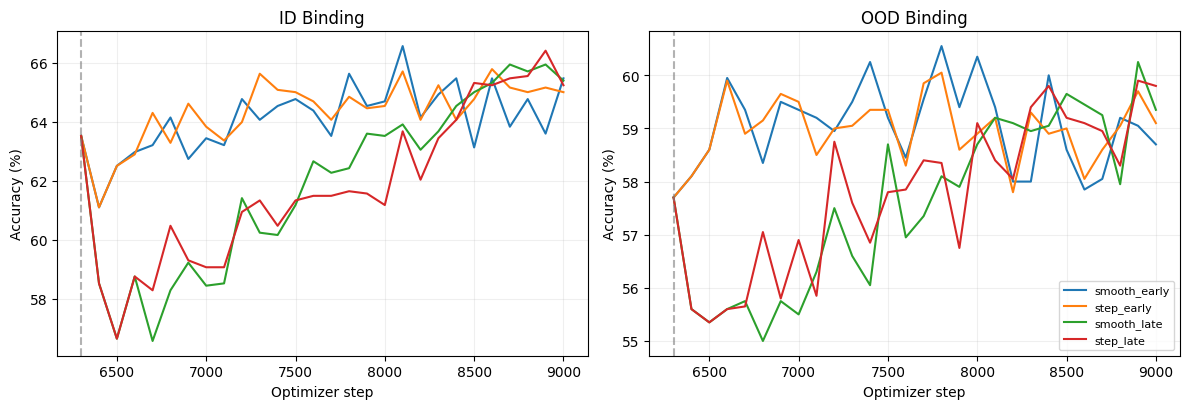

final_change_pp  worst_decline_pp
strategy     task                                          
smooth_early color                   3.67              0.16
             conjunction             8.83              0.00
             shape                   8.91              0.00
smooth_late  color                   3.20              0.08
             conjunction             7.42              0.00
             shape                   8.91              0.55
step_early   color                   3.83              0.23
             conjunction             7.97              0.00
             shape                   9.45              0.16
step_late    color                   3.20              0.08
             conjunction             7.11              0.00
             shape                   8.67              0.00

In [5]:
curves=[]
for r in runs:
    for h in r["history"]:
        curves.append({"seed":r["seed"],"strategy":r["schedule"],"step":h["step"],
                       "id_binding":h["id_dev"]["by_template"]["pair"],
                       "ood_binding":h["ood_dev"]["by_template"]["pair"],
                       **{f"id_{t}":h["id_dev"]["by_template"][t] for t in TASKS if t!="pair"},
                       "pair_presentations":h["cumulative_task_presentations"].get("pair",0)})
curves=pd.DataFrame(curves)
curves.to_csv(OUT_DIR/"learning_curves.csv",index=False)
fig,axes=plt.subplots(1,2,figsize=(12,4.2))
for s in STRATEGIES:
    avg=curves[(curves.strategy==s)&(curves.step>=6300)].groupby("step")[
        ["id_binding","ood_binding"]].mean()
    axes[0].plot(avg.index,100*avg.id_binding,label=s)
    axes[1].plot(avg.index,100*avg.ood_binding,label=s)
for ax,title in zip(axes,("ID Binding","OOD Binding")):
    ax.axvline(6300,color="grey",ls="--",alpha=.6)
    ax.set(title=title,xlabel="Optimizer step",ylabel="Accuracy (%)")
    ax.grid(alpha=.2)
axes[1].legend(fontsize=8);fig.tight_layout()
fig.savefig(OUT_DIR/"binding_learning_curves.png",dpi=160);plt.show()
retention=[]
for (seed,strategy),part in curves.groupby(["seed","strategy"]):
    part=part.set_index("step")
    for task in ("color","shape","conjunction"):
        col=f"id_{task}";initial=float(part.loc[6300,col]);final_acc=float(part.loc[9000,col])
        worst=float(part.loc[6300:9000,col].min())
        retention.append({"seed":seed,"strategy":strategy,"task":task,
                          "parent_accuracy":initial,"final_accuracy":final_acc,
                          "final_change_pp":100*(final_acc-initial),
                          "worst_decline_pp":100*(initial-worst)})
retention=pd.DataFrame(retention)
retention.to_csv(OUT_DIR/"earlier_task_retention.csv",index=False)
display(retention.groupby(["strategy","task"])[["final_change_pp","worst_decline_pp"]].mean().round(2))

## Prediction-level changes

Analyze 6,300→9,000 for retained/forgotten/newly learned questions; 7,200→7,300 tests local disruption, although strategies have different task allocations at that point. Recovery denotes correct→incorrect→correct at three specified checkpoints, not persistent correctness.

In [6]:
windows=[(6300,9000),(7200,7300),(7200,9000)]
change_rows=[]
for r in runs:
    for split in ("id_dev","ood_dev"):
        b=traces[(r["seed"],r["schedule"])]["splits"][split]
        for start,end in windows:
            ch=compare_two(b,start,end)
            for _,row in summarize_changes(ch).iterrows():
                change_rows.append({"seed":r["seed"],"strategy":r["schedule"],
                                    "split":split,"start":start,"end":end,**row.to_dict()})
changes=pd.DataFrame(change_rows)
changes.to_csv(OUT_DIR/"prediction_change_summary.csv",index=False)
view=changes[(changes.task=="pair") & (changes.start==6300) & (changes.end==9000)]
display(view.groupby(["strategy","split"])[["accuracy_before","accuracy_after",
    "forgetting_rate","newly_learned_rate","correctness_churn"]].mean().round(3))
recovery=[]
for r in runs:
    for split in ("id_dev","ood_dev"):
        b=traces[(r["seed"],r["schedule"])]["splits"][split]
        ch=compare_three(b,6300,7200,9000)
        for _,row in summarize_changes(ch).iterrows():
            recovery.append({"seed":r["seed"],"strategy":r["schedule"],"split":split,**row.to_dict()})
recovery=pd.DataFrame(recovery)
recovery.to_csv(OUT_DIR/"recovery_summary.csv",index=False)
display(recovery[recovery.task=="pair"].groupby(["strategy","split"])[
    ["forgetting_rate","recovery_rate_among_forgotten"]].mean().round(3))

accuracy_before  accuracy_after  forgetting_rate  \
strategy     split                                                       
smooth_early id_dev             0.635           0.655            0.135   
             ood_dev            0.577           0.587            0.169   
smooth_late  id_dev             0.635           0.654            0.137   
             ood_dev            0.577           0.593            0.127   
step_early   id_dev             0.635           0.650            0.140   
             ood_dev            0.577           0.591            0.169   
step_late    id_dev             0.635           0.652            0.131   
             ood_dev            0.577           0.598            0.123   

                      newly_learned_rate  correctness_churn  
strategy     split                                           
smooth_early id_dev                0.288              0.191  
             ood_dev               0.256              0.206  
smooth_late  id_dev                0.285              0.192  
             ood_dev               0.216              0.164  
step_early   id_dev                0.283              0.193  
             ood_dev               0.264              0.209  
step_late    id_dev                0.271              0.183  
             ood_dev               0.221              0.165

forgetting_rate  recovery_rate_among_forgotten
strategy     split                                                  
smooth_early id_dev             0.099                          0.434
             ood_dev            0.107                          0.389
smooth_late  id_dev             0.200                          0.615
             ood_dev            0.197                          0.563
step_early   id_dev             0.115                          0.393
             ood_dev            0.116                          0.411
step_late    id_dev             0.170                          0.629
             ood_dev            0.174                          0.583

## Final OOD errors by combination and scene complexity

Use subgroup counts and label support, not only raw accuracy, to distinguish false positives from false negatives.

In [7]:
meta={split:list(read_jsonl(DATA_DIR/("id_dev.jsonl" if split=="id_dev" else "ood_dev.jsonl")))
      for split in ("id_dev","ood_dev")}
subgroup_rows=[]
for r in runs:
    for split in ("id_dev","ood_dev"):
        b=traces[(r["seed"],r["schedule"])]["splits"][split]
        data=pd.DataFrame({"example_id":b["ids"],"task":b["tasks"],
                           "label":b["labels"],"prediction":b["predictions"][-1]})
        data=scene_context(data,meta[split])
        data=data[data.task=="pair"].copy()
        data["target_pair"]=data.target_color+"–"+data.target_shape
        for attr in ("target_pair","target_color","target_shape","n_objects","n_colors","n_shapes"):
            for value,part in data.groupby(attr):
                y,p=part.label.to_numpy(),part.prediction.to_numpy()
                tp=int(((p==1)&(y==1)).sum());fn=int(((p==0)&(y==1)).sum())
                tn=int(((p==0)&(y==0)).sum());fp=int(((p==1)&(y==0)).sum())
                subgroup_rows.append({"seed":r["seed"],"strategy":r["schedule"],
                    "split":split,"attribute":attr,"value":value,"n":len(part),
                    "positive_n":int((y==1).sum()),"negative_n":int((y==0).sum()),
                    "tp":tp,"fn":fn,"tn":tn,"fp":fp,"accuracy":(tp+tn)/len(part)})
subgroups=pd.DataFrame(subgroup_rows)
subgroups.to_csv(OUT_DIR/"prediction_error_subgroups.csv",index=False)
t= subgroups[(subgroups.split=="ood_dev")&(subgroups.attribute=="target_pair")]
display(t.groupby(["strategy","value"])[["n","tp","fn","tn","fp"]].sum()
        .assign(accuracy=lambda x:(x.tp+x.tn)/x.n).round(3))

n   tp   fn   tn   fp  accuracy
strategy     value                                             
smooth_early blue–square      485  188   52  119  126     0.633
             green–circle     545  219   56  139  131     0.657
             purple–triangle  555  144  136  142  133     0.515
             red–crescent     415  118   87  105  105     0.537
smooth_late  blue–square      485  212   28   95  150     0.633
             green–circle     545  223   52  159  111     0.701
             purple–triangle  555  153  127  123  152     0.497
             red–crescent     415  127   78   95  115     0.535
step_early   blue–square      485  191   49  122  123     0.645
             green–circle     545  211   64  151  119     0.664
             purple–triangle  555  138  142  149  126     0.517
             red–crescent     415  116   89  104  106     0.530
step_late    blue–square      485  202   38  103  142     0.629
             green–circle     545  219   56  157  113     0.690
             purple–triangle  555  168  112  125  150     0.528
             red–crescent     415  126   79   96  114     0.535